# Parcial 1 — Teoría de Aprendizaje de Máquina
## Métodos kernel, espacios de características y formulación matricial

**Ever Hernández y Juan David Villota**

**Semilla:** `20261011`

| Sección | Qué hacemos |
|---------|-------------|
| **1.5** | LS, RLS, ML y MAP |
| **2.4** | MMD MNIST vs Fashion-MNIST (con gráficas) |
| **2.4.10** | Similitud y MMD² entre las clases 0–9 de MNIST |

> Notebook **autocontenido**: genera los datos y carga MNIST/Fashion
> desde `torchvision` (o OpenML). No necesita `.npz` ni `.json` previos.

## 0. Preparación

Imports, semilla y carpeta de la caché de datasets.

### Explicación — Preparación

- **`numpy`**: vectores y matrices.
- **`matplotlib`**: figuras.
- **`SEED = 20261011`**: mismo orden aleatorio siempre (reproducible).
- **`plt.rcParams`**: imágenes en gris y tamaño de figura legible.

**Qué mirar:** que imprima la versión de NumPy y la semilla.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True, linewidth=100)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["image.cmap"] = "gray"

SEED = 20261011
rng = np.random.default_rng(SEED)

print("NumPy:", np.__version__)
print("Semilla:", SEED)

NumPy: 2.5.3
Semilla: 20261011


---
# 1.5 — Cuatro estimadores de regresión

**Idea.** Modelo lineal en un espacio de características
$\phi(x)\in\mathbb{R}^{Q}$:

$$
t = \Phi w + \eta
$$

| Método | Solución |
|--------|----------|
| LS | $(\Phi^\top\Phi)^{-1}\Phi^\top t$ |
| RLS | $(\Phi^\top\Phi+\lambda I)^{-1}\Phi^\top t$ |
| ML | = LS (ruido gaussiano) |
| MAP | = RLS si $\lambda=\sigma_\eta^2/\sigma_w^2$ |

### Explicación — 1.5.1 Generar datos

1. **Tamaños del enunciado:** $N=300$, $P=5$, $Q=20$.
2. **`X`**: 300 filas × 5 columnas, cada número $\sim\mathcal{N}(0,1)$.
3. **`Phi`** (matriz de diseño) con 20 columnas:
   - 5 valores originales,
   - 5 cuadrados,
   - 10 productos $x_i x_j$ con $i<j$ (orden fijo).
4. **`w_star`**: pesos verdaderos que el modelo debería recuperar.
5. **`eta`**: ruido $\mathcal{N}(0,0.5^2)$.
6. **`t = Phi @ w_star + eta`**: respuestas observadas.

**Qué mirar:** `Phi (300, 20)` y la lista de nombres (el orden es parte del experimento).

In [17]:
# ---- 1.5.1 Datos ----
N, P, Q = 300, 5, 20
SIGMA_ETA = 0.5
SIGMA_ETA2 = SIGMA_ETA ** 2      # 0.25
LAMBDA = 1.0
SIGMA_W2 = SIGMA_ETA2 / LAMBDA   # 0.25
TRAIN_FRAC = 0.8

# Entradas X ~ N(0,1)
X = rng.normal(size=(N, P))      # (300, 5)

# Phi(X): 5 originales + 5 cuadrados + 10 productos i<j
cols, names = [], []
for i in range(P):
    cols.append(X[:, i]);          names.append(f"x{i+1}")
for i in range(P):
    cols.append(X[:, i] ** 2);     names.append(f"x{i+1}^2")
for i in range(P):
    for j in range(i + 1, P):
        cols.append(X[:, i] * X[:, j]); names.append(f"x{i+1}*x{j+1}")

Phi = np.column_stack(cols)       # (300, 20)

w_star = rng.normal(size=Q)                 # (20,)
eta = rng.normal(scale=SIGMA_ETA, size=N)   # (300,)
t = Phi @ w_star + eta                      # (300,)

print("X", X.shape, "| Phi", Phi.shape, "| t", t.shape)
print("20 columnas:", names)
print(f"||w*||^2 = {np.sum(w_star**2):.6f}")

X (300, 5) | Phi (300, 20) | t (300,)
20 columnas: ['x1', 'x2', 'x3', 'x4', 'x5', 'x1^2', 'x2^2', 'x3^2', 'x4^2', 'x5^2', 'x1*x2', 'x1*x3', 'x1*x4', 'x1*x5', 'x2*x3', 'x2*x4', 'x2*x5', 'x3*x4', 'x3*x5', 'x4*x5']
||w*||^2 = 16.685297


### Explicación — 1.5.2 Separar train / test

- **`rng.permutation(N)`** desordena los índices $0..299$.
- **80 % train (240)** para estimar $w$; **20 % test (60)** solo para evaluar.

**Por qué:** si ajustamos con test, el error de test queda optimista
(“hemos copiado el examen”).

**Qué mirar:** `(240, 20)` y `(60, 20)`.

In [18]:
# ---- 1.5.2 Train / test ----
idx = rng.permutation(N)
n_train = int(N * TRAIN_FRAC)   # 240
train_idx, test_idx = idx[:n_train], idx[n_train:]

Phi_tr, t_tr = Phi[train_idx], t[train_idx]
Phi_te, t_te = Phi[test_idx],  t[test_idx]

print(f"train {Phi_tr.shape}   test {Phi_te.shape}")

train (240, 20)   test (60, 20)


### Explicación — 1.5.3 Ajustar los 4 modelos

1. **`PhiT_Phi`** $=\Phi^\top\Phi$ y **`PhiT_t`** $=\Phi^\top t$
   son las piezas de las ecuaciones normales.
2. **`np.linalg.solve(A, b)`** resuelve $Aw=b$ (mejor que invertir).
3. **LS** $=(\Phi^\top\Phi)^{-1}\Phi^\top t$.
4. **ML** es idéntico a LS con ruido gaussiano → `w_ml = w_ls.copy()`.
5. **RLS** usa $(\Phi^\top\Phi+\lambda I)$ con $\lambda=1$.
6. **MAP** es igual a RLS si $\lambda=\sigma_\eta^2/\sigma_w^2=1$.

**Qué mirar:**
- `max|w_ls-w_ml| = 0` y `max|w_rls-w_map| = 0` (teoría confirmada).
- `max|w_ls-w_rls| > 0` (la regularización sí cambia $w$).

In [19]:
# ---- 1.5.3 Estimadores ----
PhiT_Phi = Phi_tr.T @ Phi_tr      # (20, 20)
PhiT_t = Phi_tr.T @ t_tr          # (20,)

# LS = ML
w_ls = np.linalg.solve(PhiT_Phi, PhiT_t)
w_ml = w_ls.copy()

# RLS = MAP  (lambda = sigma_eta^2 / sigma_w^2 = 1)
lam_map = SIGMA_ETA2 / SIGMA_W2
assert abs(lam_map - LAMBDA) < 1e-12

A_reg = PhiT_Phi + LAMBDA * np.eye(Q)
w_rls = np.linalg.solve(A_reg, PhiT_t)
w_map = w_rls.copy()

print("lambda_MAP =", lam_map)
print("max|w_ls-w_ml|   =", np.max(np.abs(w_ls - w_ml)))
print("max|w_rls-w_map| =", np.max(np.abs(w_rls - w_map)))
print("max|w_ls-w_rls|  =", np.max(np.abs(w_ls - w_rls)))

lambda_MAP = 1.0
max|w_ls-w_ml|   = 0.0
max|w_rls-w_map| = 0.0
max|w_ls-w_rls|  = 0.00603106775786677


### Explicación — 1.5.4 Calcular métricas

- **`mse`**: promedio de $(t-\Phi w)^2$ en train o en test.
- **`error_pesos`**: $\|w-w^*\|^2$ (qué tan cerca está del valor real).
- Se recorren LS, ML, RLS, MAP y se imprimen juntos.

**Qué mirar en la tabla:**
- LS y ML con **exactamente** los mismos números.
- RLS y MAP, también.
- RLS con MSE de test un poco menor que LS (más generaliza).

In [20]:
# ---- 1.5.4 Métricas ----
def mse(Phi_m, t_m, w):
    # Error cuadratico medio
    err = t_m - Phi_m @ w
    return float(np.mean(err ** 2))

def error_pesos(w):
    # || w_hat - w* ||^2
    return float(np.sum((w - w_star) ** 2))

resultados = []
for nombre, w in [("LS", w_ls), ("ML", w_ml), ("RLS", w_rls), ("MAP", w_map)]:
    resultados.append({
        "Est": nombre,
        "MSE_train": mse(Phi_tr, t_tr, w),
        "MSE_test": mse(Phi_te, t_te, w),
        "||w-w*||2": error_pesos(w),
        "||w||2": float(np.sum(w ** 2)),
    })

print(f"{'Est':>5} {'MSE_train':>12} {'MSE_test':>12} {'||w-w*||2':>12} {'||w||2':>12}")
print("-" * 58)
for r in resultados:
    print(f"{r['Est']:>5} {r['MSE_train']:12.6f} {r['MSE_test']:12.6f} "
          f"{r['||w-w*||2']:12.6f} {r['||w||2']:12.6f}")
print(f"Referencia: ||w*||^2 = {np.sum(w_star**2):.6f}   sigma_eta^2 = {SIGMA_ETA2}")

  Est    MSE_train     MSE_test    ||w-w*||2       ||w||2
----------------------------------------------------------
   LS     0.220873     0.300059     0.014807    17.202845
   ML     0.220873     0.300059     0.014807    17.202845
  RLS     0.221127     0.294384     0.013067    17.081085
  MAP     0.221127     0.294384     0.013067    17.081085
Referencia: ||w*||^2 = 16.685297   sigma_eta^2 = 0.25


### Explicación — 1.5.5 Figura de 1.5

- **Izquierda:** MSE de test. La línea roja es el piso del ruido $\sigma_\eta^2=0.25$.
- **Derecha:** distancia de los pesos estimados al verdadero $w^*$.
- Color azul = sin regularizar (LS/ML); verde = con regularización (RLS/MAP).

**Qué mirar:** barras iguales dentro de cada pareja de color.

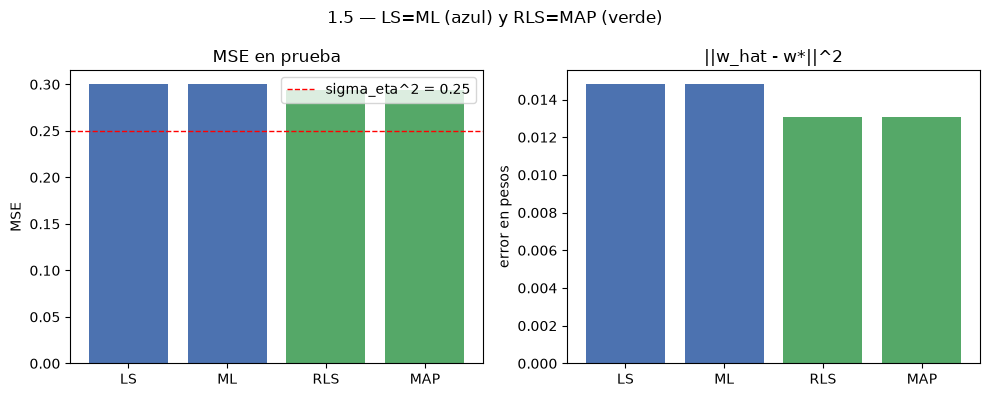

In [21]:
# ---- 1.5.5 Figura comparativa ----
nombres = [r["Est"] for r in resultados]
mse_test = [r["MSE_test"] for r in resultados]
err_w = [r["||w-w*||2"] for r in resultados]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(nombres, mse_test, color=["#4C72B0", "#4C72B0", "#55A868", "#55A868"])
axes[0].set_title("MSE en prueba")
axes[0].set_ylabel("MSE")
axes[0].axhline(SIGMA_ETA2, color="red", ls="--", lw=1, label="sigma_eta^2 = 0.25")
axes[0].legend()

axes[1].bar(nombres, err_w, color=["#4C72B0", "#4C72B0", "#55A868", "#55A868"])
axes[1].set_title("||w_hat - w*||^2")
axes[1].set_ylabel("error en pesos")

fig.suptitle("1.5 — LS=ML (azul) y RLS=MAP (verde)")
fig.tight_layout()
plt.show()

### Resumen 1.5
LS y ML coinciden; RLS y MAP coinciden. $\lambda=1$ mejora un poco la
prueba a cambio de un pelín más de sesgo en train.

---
# 2.4 — MMD entre MNIST y Fashion-MNIST

**Idea.** Medir en un RKHS (kernel gaussiano) qué tan distintas son las
distribuciones de los dos datasets, y comparar con el “ruido” de partir
un mismo dataset en dos mitades.

$$
\widehat{\mathrm{MMD}}^2_b
= \frac{1}{n^2}1^\top K_{XX}1
+ \frac{1}{m^2}1^\top K_{YY}1
- \frac{2}{nm}1^\top K_{XY}1
$$

### Explicación — 2.4.1 Cargar los datasets

1. **`torchvision.datasets.MNIST` / `FashionMNIST`**
   - Trae el split de **entrenamiento** oficial.
   - `download=True` lo baja la primera vez a `data_torchvision/`.

2. **`transforms.ToTensor()`**
   - Convierte cada imagen PIL en tensor con píxeles en $[0,1]$.

3. **No usamos etiquetas de clase** (el enunciado lo pide así): solo
   comparamos distribuciones de imágenes.

**Qué mirar:** `60000` imágenes en cada dataset y la forma `torch.Size([1, 28, 28])`.

In [22]:
# ---- 2.4.1 Cargar MNIST y Fashion-MNIST (sin archivos previos) ----
from torchvision import datasets, transforms

DATA_DIR = "data_torchvision"   # solo caché de descarga

to_tensor = transforms.ToTensor()   # imagen -> tensor [0,1] de 1x28x28

print("Descargando / cargando MNIST ...")
mnist_ds = datasets.MNIST(DATA_DIR, train=True, download=True, transform=to_tensor)
print("Descargando / cargando Fashion-MNIST ...")
fashion_ds = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=to_tensor)

print("MNIST:", len(mnist_ds), "imágenes de entrenamiento")
print("Fashion:", len(fashion_ds), "imágenes de entrenamiento")
print("ejemplo:", mnist_ds[0][0].shape, "etiqueta (no la usamos):", mnist_ds[0][1])

Descargando / cargando MNIST ...
Descargando / cargando Fashion-MNIST ...
MNIST: 60000 imágenes de entrenamiento
Fashion: 60000 imágenes de entrenamiento
ejemplo: torch.Size([1, 28, 28]) etiqueta (no la usamos): 5


### Explicación — 2.4.2 Muestras de 500+500

1. **`tomar_imagenes`** escoge 1000 índices al azar (sin repetición).
2. Cada imagen $28\times 28$ se **aplana** a un vector de 784 números.
3. Se parte en dos mitades de 500:
   - `mnist0` / `mnist1`
   - `fashion0` / `fashion1`

**Comparaciones del enunciado:**
- A: `mnist0` vs `fashion0` (entre datasets)
- B: `mnist0` vs `mnist1` (mismo dataset)
- C: `fashion0` vs `fashion1` (mismo dataset)

**Qué mirar:** formas `(500, 784)` y píxeles en $[0,1]$.

In [23]:
# ---- 2.4.2 Elegir 1000 imgs por dataset y hacer los grupos de 500 ----
def tomar_imagenes(ds, n_total=1000, seed=SEED):
    # n_total imagenes al azar del dataset, aplanadas a 784 pixeles en [0,1]
    g = np.random.default_rng(seed)
    idx = g.choice(len(ds), size=n_total, replace=False)
    X = np.zeros((n_total, 784), dtype=np.float64)
    for k, i in enumerate(idx):
        img = ds[i][0].numpy().reshape(-1)   # (1,28,28) -> (784,)
        X[k] = img
    return X, idx

mnist_1000, idx_m = tomar_imagenes(mnist_ds, 1000, SEED)
fashion_1000, idx_f = tomar_imagenes(fashion_ds, 1000, SEED)

# dos grupos disjuntos de 500
mnist0, mnist1 = mnist_1000[:500], mnist_1000[500:]
fashion0, fashion1 = fashion_1000[:500], fashion_1000[500:]

print("mnist0", mnist0.shape, " mnist1", mnist1.shape)
print("fashion0", fashion0.shape, " fashion1", fashion1.shape)
print("pixeles en [0,1]?", mnist0.min() >= 0 and mnist0.max() <= 1)

mnist0 (500, 784)  mnist1 (500, 784)
fashion0 (500, 784)  fashion1 (500, 784)
pixeles en [0,1]? True


### Explicación — 2.4.3 Dibujar MNIST y Fashion

1. **`reshape(28, 28)`** devuelve la forma de imagen.
2. **`imshow(..., cmap='gray', vmin=0, vmax=1)`** pinta la escala de grises.
3. Se muestran 8 de cada dataset.

**Qué mirar:** dígitos (MNIST) y prendas (Fashion). Si se ven raras,
algo falló en la carga o normalización.

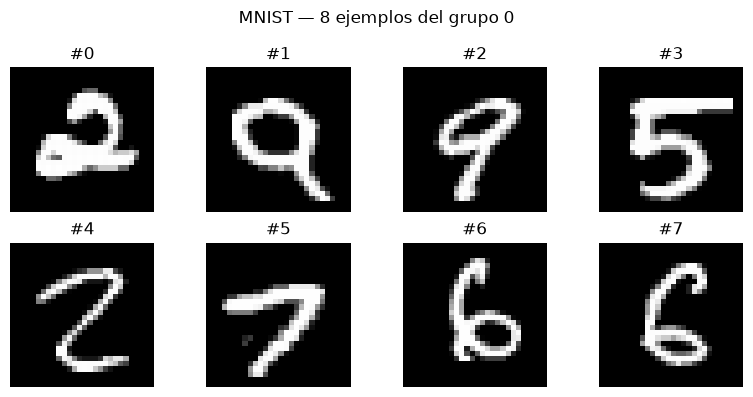

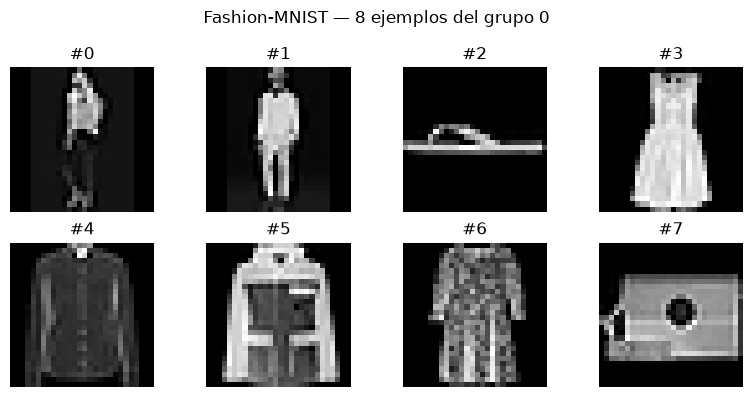

In [24]:
# ---- 2.4.3 VER las imágenes ----
def mostrar_imagenes(X, titulo, n=8):
    fig, axes = plt.subplots(2, 4, figsize=(8, 4))
    fig.suptitle(titulo)
    for ax, k in zip(axes.ravel(), range(n)):
        ax.imshow(X[k].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        ax.set_title(f"#{k}")
    plt.tight_layout()
    plt.show()

mostrar_imagenes(mnist0, "MNIST — 8 ejemplos del grupo 0")
mostrar_imagenes(fashion0, "Fashion-MNIST — 8 ejemplos del grupo 0")

### Explicación — 2.4.4 Kernel y fórmula de MMD

1. **`kernel_gaussiano`**
   $$k(u,v)=\exp\left(-\frac{\|u-v\|^2}{2\sigma^2}\right)$$
   - Usa $\|u-v\|^2 = \|u\|^2+\|v\|^2-2u^\top v$ (eficiente con matrices).

2. **`mmd2_sesgado`**
   - `unos @ K @ unos` suma **todas** las entradas de $K$.
   - Es la forma matricial del estimador sesgado del punto 2.3.

**Qué mirar:** solo que las funciones se definan sin error; los números
salen en la celda siguiente.

In [25]:
# ---- 2.4.4 Kernel gaussiano y MMD ----
def kernel_gaussiano(U, V, sigma):
    # K[i,j] = exp( -||U[i]-V[j]||^2 / (2 sigma^2) )
    u2 = np.sum(U * U, axis=1)[:, None]
    v2 = np.sum(V * V, axis=1)[None, :]
    d2 = np.maximum(u2 + v2 - 2.0 * (U @ V.T), 0.0)
    return np.exp(-d2 / (2.0 * sigma ** 2))

def mmd2_sesgado(KXX, KYY, KXY):
    # 1/n^2 1'KXX 1 + 1/m^2 1'KYY 1 - 2/(nm) 1'KXY 1
    n, m = KXX.shape[0], KYY.shape[0]
    unos_n, unos_m = np.ones(n), np.ones(m)
    t_xx = (unos_n @ KXX @ unos_n) / (n * n)
    t_yy = (unos_m @ KYY @ unos_m) / (m * m)
    t_xy = (unos_n @ KXY @ unos_m) / (n * m)
    return float(t_xx + t_yy - 2.0 * t_xy)

print("Funciones listas: kernel_gaussiano, mmd2_sesgado")

Funciones listas: kernel_gaussiano, mmd2_sesgado


### Explicación — 2.4.5 Elegir $\sigma$ (mediana de distancias)

1. Se juntan 250 imágenes de MNIST y Fashion (muestra combinada).
2. Se calculan las distancias euclidianas entre pares $i<j$.
3. $\sigma$ = **mediana** de esas distancias.

**Por qué la mediana:** es un ancho de banda típico (ni muy local ni muy
suave). El enunciado pide el **mismo $\sigma$** en todas las comparaciones
para que los MMD sean comparables.

**Qué mirar:** `mediana (sigma) ≈ 11.07`.

In [26]:
# ---- 2.4.5 Sigma por heuristica de la mediana ----
# Se combinan 250 imagenes de mnist0 + fashion0 y se toma la mediana
# de las distancias euclidianas por pares.

g = np.random.default_rng(SEED)
ref = np.vstack([mnist0, fashion0])          # (1000, 784)
sel = g.choice(len(ref), size=250, replace=False)
sub = ref[sel]                                # (250, 784)

# distancias por pares (i < j)
d2 = np.maximum(
    np.sum(sub*sub, axis=1)[:,None] + np.sum(sub*sub, axis=1)[None,:] - 2*(sub @ sub.T),
    0.0,
)
iu = np.triu_indices(250, k=1)
dist = np.sqrt(d2[iu])
sigma = float(np.median(dist))

print(f"pares = {len(dist)}")
print(f"distancia min = {dist.min():.4f}")
print(f"mediana (sigma) = {sigma:.6f}")
print(f"distancia max = {dist.max():.4f}")

pares = 31125
distancia min = 1.5294
mediana (sigma) = 11.068824
distancia max = 18.8125


### Explicación — 2.4.6 Mapa de calor de las Gram

1. Con solo **50** imágenes la figura se distingue (con 500 sería una mancha).
2. **$K_{XX}$ (MNIST–MNIST):** diagonal en 1 ($k(x,x)=1$); celdas claras =
   imágenes parecidas.
3. **$K_{XY}$ (MNIST–Fashion):** suele verse más oscura (menos similitud).

**Qué mirar:** que la media de $K_{XY}$ sea menor que la de $K_{XX}$.

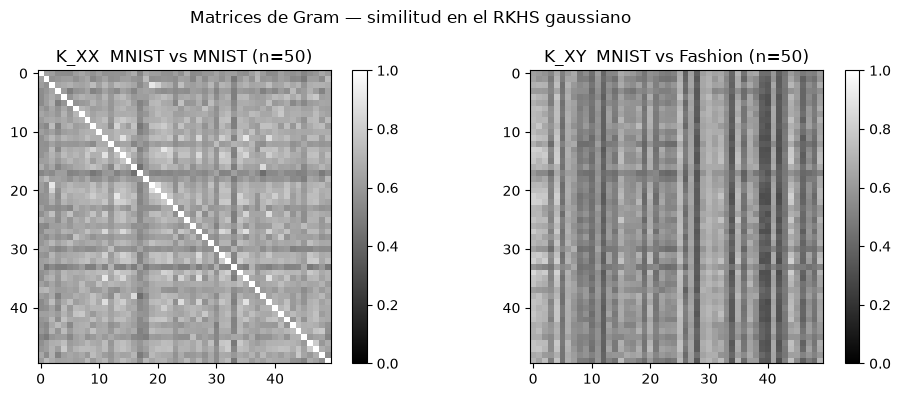

media Kxx_demo = 0.6589172981227923
media Kxy_demo = 0.5588546857117686


In [27]:
# ---- 2.4.6 Heatmap de matrices de Gram ----
sub_n = 50
Kxx_demo = kernel_gaussiano(mnist0[:sub_n], mnist0[:sub_n], sigma)
Kxy_demo = kernel_gaussiano(mnist0[:sub_n], fashion0[:sub_n], sigma)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].imshow(Kxx_demo, vmin=0, vmax=1)
axes[0].set_title(f"K_XX  MNIST vs MNIST (n={sub_n})")
fig.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(Kxy_demo, vmin=0, vmax=1)
axes[1].set_title(f"K_XY  MNIST vs Fashion (n={sub_n})")
fig.colorbar(im1, ax=axes[1], fraction=0.046)

fig.suptitle("Matrices de Gram — similitud en el RKHS gaussiano")
fig.tight_layout()
plt.show()

print("media Kxx_demo =", Kxx_demo.mean())
print("media Kxy_demo =", Kxy_demo.mean())

### Explicación — 2.4.7 Calcular los tres MMD

- **`mmd_entre(X, Y, sigma)`** arma $K_{XX}$, $K_{YY}$, $K_{XY}$ y aplica
  el estimador sesgado.
- Tres corridas: A (entre datasets), B y C (intra-dataset).

**Qué mirar:** A ≈ 0.13 y B, C ≈ 0.001 (muy por debajo).

In [28]:
# ---- 2.4.7 MMD de las 3 comparaciones ----
# A: MNIST0 vs Fashion0 | B: MNIST0 vs MNIST1 | C: Fashion0 vs Fashion1

def mmd_entre(X, Y, sigma):
    KXX = kernel_gaussiano(X, X, sigma)
    KYY = kernel_gaussiano(Y, Y, sigma)
    KXY = kernel_gaussiano(X, Y, sigma)
    return mmd2_sesgado(KXX, KYY, KXY)

mmd_a = mmd_entre(mnist0, fashion0, sigma)
mmd_b = mmd_entre(mnist0, mnist1, sigma)
mmd_c = mmd_entre(fashion0, fashion1, sigma)

print(f"A  MNIST vs Fashion    MMD^2 = {mmd_a:.6f}")
print(f"B  MNIST vs MNIST      MMD^2 = {mmd_b:.6f}")
print(f"C  Fashion vs Fashion  MMD^2 = {mmd_c:.6f}")
print("\nLectura: A >> B,C  =>  los datasets son distintos en el RKHS")

A  MNIST vs Fashion    MMD^2 = 0.127426
B  MNIST vs MNIST      MMD^2 = 0.001366
C  Fashion vs Fashion  MMD^2 = 0.000888

Lectura: A >> B,C  =>  los datasets son distintos en el RKHS


### Explicación — 2.4.9 ¿Importa el valor de $\sigma$?

Se repite el MMD con $\sigma/2$, $\sigma$ y $2\sigma$.

- $\sigma$ grande → kernel suave → MMD chico (se pierde señal).
- $\sigma$ chico → kernel local → más ruido de alta frecuencia.

**Qué mirar:** la curva A baja al agrandar $\sigma$.

x0.5  sigma=5.5344   A=0.115803   B=0.003181
x1.0  sigma=11.0688   A=0.127426   B=0.001366
x2.0  sigma=22.1376   A=0.049002   B=0.000402


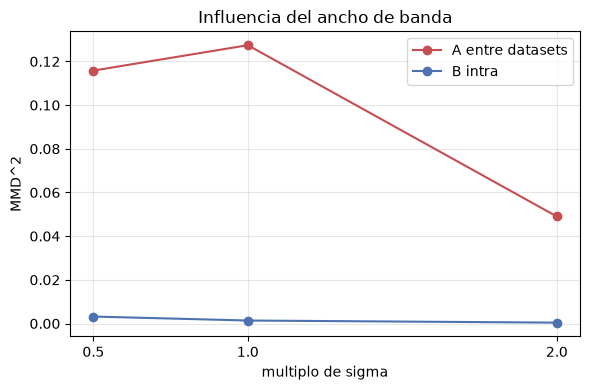

In [29]:
# ---- 2.4.9 Sensibilidad a sigma ----
multiplos = [0.5, 1.0, 2.0]
mmd_A, mmd_B = [], []
for mult in multiplos:
    s = sigma * mult
    mmd_A.append(mmd_entre(mnist0, fashion0, s))
    mmd_B.append(mmd_entre(mnist0, mnist1, s))
    print(f"x{mult:.1f}  sigma={s:.4f}   A={mmd_A[-1]:.6f}   B={mmd_B[-1]:.6f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(multiplos, mmd_A, "o-", color="#C44E52", label="A entre datasets")
ax.plot(multiplos, mmd_B, "o-", color="#4C72B0", label="B intra")
ax.set_xlabel("multiplo de sigma")
ax.set_ylabel("MMD^2")
ax.set_title("Influencia del ancho de banda")
ax.set_xticks(multiplos)
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

### Análisis 2.4
| Caso | MMD$^2$ |
|------|---------|
| A entre datasets | **~0.13** |
| B / C intra | ~0.001 |

Los datasets son distintos en el RKHS. Un MMD no es un $p$-value: es un
tamaño de efecto (hace falta un test formal para afirmar $P_X\ne P_Y$).

### Explicación — 2.4.10 ¿Qué tan parecidas son las clases 0–9?

Mismo estimador de 2.4.7, ahora **entre clases** de MNIST: se toman `PCL`
imágenes al azar de cada dígito (`PCL = 500`, el mismo $n$ de 2.4.7) y se
construyen dos matrices $10\times10$:

- **`S[i,j]`**: similitud media $k(x,y)$ entre las clases $i$ y $j$
  (media de todas las entradas de $K_{ij}$). Cerca de 1 = muy parecidas.
- **`MMD2c[i,j]`**: $\widehat{\mathrm{MMD}}^2_b$ entre ambas clases, con el
  **mismo $\sigma$** de 2.4.5. Cerca de 0 = muy parecidas.

Los prototipos (imagen promedio por dígito) ayudan a leer las matrices.

> **Nota:** aquí sí usamos las etiquetas, pero solo para agrupar por dígito.
> La comparación de 2.4.7 sigue sin usarlas.


muestras: 10 clases x 500 imagenes = (5000, 784)   sigma = 11.068824
similitud k(x,y): diagonal = 0.665-0.841   fuera de la diagonal = 0.587-0.706


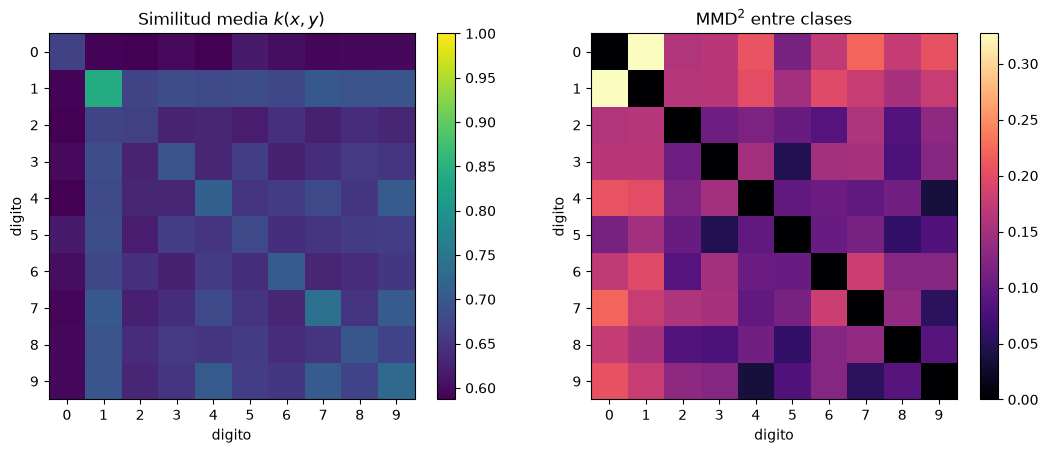

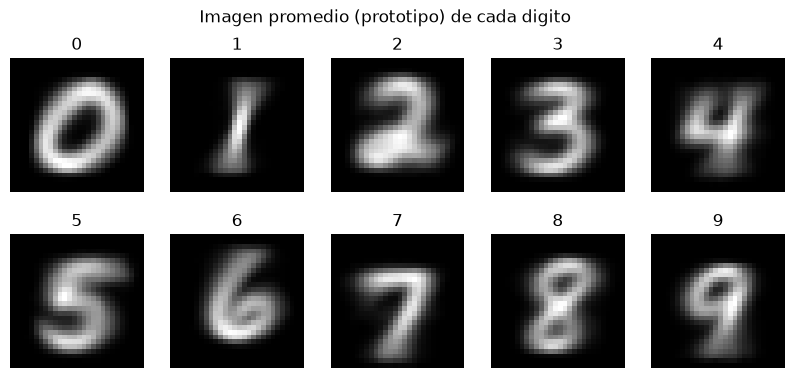

pares de digitos mas parecidos (menor MMD^2):
  4-9: MMD^2=0.03648
  3-5: MMD^2=0.04611
  7-9: MMD^2=0.05462
  5-8: MMD^2=0.05992
  3-8: MMD^2=0.08008
  5-9: MMD^2=0.08367


In [30]:
# ---- 2.4.10 Que tan parecidas son las clases 0-9 de MNIST ----
# Las etiquetas se usan SOLO para agrupar por digito (2.4.7 no las usa).
PCL = 500                     # imagenes por clase: mismo n que en 2.4.7
N_CLASES = 10

etiquetas_mnist = np.asarray(mnist_ds.targets)
g_cl = np.random.default_rng(SEED + 1)

Xd = np.zeros((N_CLASES * PCL, 784), dtype=np.float64)
for d in range(N_CLASES):
    sel = g_cl.choice(np.flatnonzero(etiquetas_mnist == d), size=PCL, replace=False)
    Xd[d * PCL:(d + 1) * PCL] = [mnist_ds[int(i)][0].numpy().reshape(-1) for i in sel]

# S[i,j] = similitud media k(x,y) entre las clases i y j
# MMD2c[i,j] = MMD^2 sesgado entre las clases i y j (mismo sigma de 2.4.5)
S = np.zeros((N_CLASES, N_CLASES))
MMD2c = np.zeros((N_CLASES, N_CLASES))
for i in range(N_CLASES):
    Xi = Xd[i * PCL:(i + 1) * PCL]
    Kii = kernel_gaussiano(Xi, Xi, sigma)
    S[i, i] = Kii.mean()
    for j in range(i + 1, N_CLASES):
        Xj = Xd[j * PCL:(j + 1) * PCL]
        Kij = kernel_gaussiano(Xi, Xj, sigma)
        S[i, j] = S[j, i] = Kij.mean()
        MMD2c[i, j] = MMD2c[j, i] = mmd2_sesgado(Kii, kernel_gaussiano(Xj, Xj, sigma), Kij)

fuera = ~np.eye(N_CLASES, dtype=bool)
print(f"muestras: {N_CLASES} clases x {PCL} imagenes = {Xd.shape}   sigma = {sigma:.6f}")
print(f"similitud k(x,y): diagonal = {np.diag(S).min():.3f}-{np.diag(S).max():.3f}   fuera de la diagonal = {S[fuera].min():.3f}-{S[fuera].max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))

im0 = ax[0].imshow(S, cmap="viridis", vmin=S.min(), vmax=1)   # 1 = muy parecidos
ax[0].set_title("Similitud media $k(x,y)$"); ax[0].set_xlabel("digito"); ax[0].set_ylabel("digito")
ax[0].set_xticks(range(10)); ax[0].set_yticks(range(10))
fig.colorbar(im0, ax=ax[0], fraction=0.046)

im1 = ax[1].imshow(MMD2c, cmap="magma")                        # 0 = muy parecidos
ax[1].set_title("MMD$^2$ entre clases"); ax[1].set_xlabel("digito"); ax[1].set_ylabel("digito")
ax[1].set_xticks(range(10)); ax[1].set_yticks(range(10))
fig.colorbar(im1, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()

# imagen promedio (prototipo) de cada digito: muestra visualmente los parecidos
fig, axs = plt.subplots(2, 5, figsize=(10, 4.2))
for d in range(10):
    axs[d // 5, d % 5].imshow(Xd[d * PCL:(d + 1) * PCL].mean(0).reshape(28, 28), cmap="gray")
    axs[d // 5, d % 5].set_title(str(d)); axs[d // 5, d % 5].axis("off")
plt.suptitle("Imagen promedio (prototipo) de cada digito"); plt.show()

# pares de digitos mas parecidos (menor MMD^2 fuera de la diagonal)
pairs = sorted((MMD2c[i, j], i, j) for i in range(10) for j in range(i + 1, 10))
print("pares de digitos mas parecidos (menor MMD^2):")
for v, i, j in pairs[:6]:
    print(f"  {i}-{j}: MMD^2={v:.5f}")


### Análisis 2.4.10 — qué tan parecidas son las clases

| Comparación (mismo $\sigma$, $n=m=500$) | MMD$^2$ |
|---|---|
| dos mitades disjuntas del **mismo** dataset (2.4.7) | 0.0014 (MNIST) / 0.0009 (Fashion) |
| **clases distintas** de MNIST (fuera de la diagonal) | 0.0365 – 0.3270 |
| MNIST vs Fashion (2.4.7) | 0.1274 |

- **Pares más parecidos:** **4–9** (0.0365), **3–5** (0.0461), **7–9** (0.0546). Los más distintos:
  **0–4** (0.2073), **0–7** (0.2217), **0–1** (0.3270). Es coherente con los prototipos: los dígitos con más
  trazos compartidos (4, 9, 7) se confunden entre sí, mientras el 0 y el 1
  son los más “atípicos”.
- **Todo par de dígitos distintos** supera el ruido muestral intra-dataset
  (~0.0014) entre $\approx27$ y $\approx239$ veces, así que
  en el RKHS cada dígito es una distribución distinguible de las demás.
- **Pero el MMD$^2$ no tiene escala absoluta:** el valor entre datasets
  (0.1274) cae *dentro* del rango entre clases de MNIST
  (0.0365–0.3270); con otro kernel dos dígitos
  podrían estar más lejos que MNIST y Fashion. Es un *tamaño de efecto*, no
  un $p$-valor: para afirmar $P_X\ne P_Y$ hace falta un contraste formal
  (p. ej. permutación), y para comparar valores entre sí, el mismo $n$ y el
  mismo $\sigma$.


---
# Resumen final

| Punto | Resultado |
|-------|-----------|
| 1.5 | LS=ML, RLS=MAP; $\lambda=1$ mejora prueba |
| 2.4 | MMD(A)≈0.13 vs MMD(B,C)≈0.001 → MNIST ≠ Fashion |
| 2.4.10 | MMD² entre clases de MNIST muy por encima del ruido muestral; 0.1274 (MNIST vs Fashion) cae dentro de ese rango |

Todo se calcula **dentro del notebook** (sin `.npz` / `.json` de resultados).